# Fighter Tie-Breaking Sensitivity Analysis

The baseline simulation uses **frequency-based tie-breaking**: when a character's stat array qualifies for multiple classes, the class that appears in the most (primary, secondary) attribute combinations wins. Fighter's broad attribute coverage means it wins this count more often than other classes.

This notebook tests the alternative: **uniform random tie-breaking**, where we select uniformly at random from all unique classes that qualify for any of the character's stat combinations. This removes the amplification effect and isolates Fighter's share that is due purely to attribute space coverage vs. tie-breaking mechanics.

In [1]:
import random
import pickle
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from tqdm import tqdm
import gen as g

## 1. Load Baseline Results

In [2]:
with open('sim_results.pkl', 'rb') as f:
    baseline_results = pickle.load(f)

# Extract class counts from each simulation run
# sim_results structure: list of tuples, index 1 is classes_count dict
baseline_class_counts = [run[1] for run in baseline_results]

all_classes = sorted(set(k for run in baseline_class_counts for k in run.keys()))

baseline_df = pd.DataFrame(
    [{cls: run.get(cls, 0) for cls in all_classes} for run in baseline_class_counts]
)

n_chars = baseline_df.sum(axis=1).iloc[0]
baseline_pct = baseline_df / n_chars * 100

print(f"Baseline: {len(baseline_results)} runs x {int(n_chars):,} characters each")
print(f"Fighter baseline: {baseline_pct['Fighter'].mean():.2f}% ± {baseline_pct['Fighter'].std():.2f}%")

Baseline: 50 runs x 10,000 characters each
Fighter baseline: 24.86% ± 0.45%


## 2. Define Random Tie-Breaking Alternative

The only change: instead of counting how many stat combinations map to each class and picking the winner, we take all unique qualifying classes and pick uniformly at random.

In [3]:
def select_class_random(sorted_stats):
    """Uniform random selection from all classes that qualify for any stat combination.
    
    Contrast with baseline select_class(), which picks the class with the highest
    count of matching attribute combinations, amplifying classes with broad coverage.
    """
    stat_combos = g.get_stat_combos(sorted_stats)
    if not stat_combos:
        return None
    potential_classes = g.query_class(stat_combos)
    if not potential_classes:
        return None
    unique_classes = list(set(c[0] for c in potential_classes))
    return random.choice(unique_classes)


def generate_random_tiebreak():
    """Full character generation using random tie-breaking for class selection."""
    dead_farmers = 0
    recommended_species = None
    chosen_class = None
    background = None

    while not (recommended_species and chosen_class and background):
        stats, attempts = g.roll_stats()
        dead_farmers += attempts
        recommended_species = g.recommend_species(stats)
        updated_stats = g.apply_species_bonus(stats, recommended_species)
        optimal_stats = g.sort_stats(updated_stats)
        chosen_class = select_class_random(optimal_stats)
        background = g.pick_background(optimal_stats)

    return recommended_species, chosen_class, background


def run_random_tiebreak_simulation(num_simulations, num_iterations):
    results = []
    for _ in tqdm(range(num_simulations), desc="Random tie-break runs"):
        class_counts = {}
        for _ in range(num_iterations):
            _, chosen_class, _ = generate_random_tiebreak()
            class_counts[chosen_class] = class_counts.get(chosen_class, 0) + 1
        results.append(class_counts)
    return results

## 3. Run Random Tie-Breaking Simulation

Using 20 runs × 3,000 characters — same scale as the feat-weight sensitivity analysis.

In [4]:
RANDOM_TB_FILE = 'fighter_tiebreak_results.pkl'
N_SIMS = 20
N_CHARS = 3000

if os.path.exists(RANDOM_TB_FILE):
    with open(RANDOM_TB_FILE, 'rb') as f:
        random_tb_results = pickle.load(f)
    print(f"Loaded cached results from {RANDOM_TB_FILE}")
else:
    random_tb_results = run_random_tiebreak_simulation(N_SIMS, N_CHARS)
    with open(RANDOM_TB_FILE, 'wb') as f:
        pickle.dump(random_tb_results, f)
    print(f"Saved to {RANDOM_TB_FILE}")

Random tie-break runs: 100%|██████████| 20/20 [14:41<00:00, 44.09s/it]

Saved to fighter_tiebreak_results.pkl


## 4. Compare Distributions

In [5]:
random_tb_df = pd.DataFrame(
    [{cls: run.get(cls, 0) for cls in all_classes} for run in random_tb_results]
)
random_tb_n = random_tb_df.sum(axis=1).iloc[0]
random_tb_pct = random_tb_df / random_tb_n * 100

# Summary table
summary = pd.DataFrame({
    'Baseline mean %': baseline_pct[all_classes].mean().round(2),
    'Baseline ± std':  baseline_pct[all_classes].std().round(2),
    'Random TB mean %': random_tb_pct[all_classes].mean().round(2),
    'Random TB ± std':  random_tb_pct[all_classes].std().round(2),
}).sort_values('Baseline mean %', ascending=False)

summary['Δ (pct pts)'] = (summary['Random TB mean %'] - summary['Baseline mean %']).round(2)

print(summary.to_string())

           Baseline mean %  Baseline ± std  Random TB mean %  Random TB ± std  Δ (pct pts)
Fighter              24.86            0.45             24.91             0.81         0.05
Ranger               13.47            0.30             13.69             0.43         0.22
Cleric               10.75            0.30             10.57             0.44        -0.18
Paladin               9.51            0.29              9.39             0.40        -0.12
Wizard                7.84            0.24              7.96             0.56         0.12
Sorcerer              7.19            0.27              7.23             0.37         0.04
Monk                  5.56            0.23              5.48             0.47        -0.08
Rogue                 5.16            0.24              5.05             0.35        -0.11
Barbarian             4.44            0.24              4.50             0.39         0.06
Bard                  4.02            0.17              4.06             0.31         0.04

In [6]:
# Headline numbers for the paper
fighter_baseline = baseline_pct['Fighter'].mean()
fighter_random   = random_tb_pct['Fighter'].mean()
fighter_delta    = fighter_random - fighter_baseline

print("Fighter's share:")
print(f"  Frequency tie-breaking (baseline): {fighter_baseline:.2f}%")
print(f"  Random tie-breaking:               {fighter_random:.2f}%")
print(f"  Δ:                                 {fighter_delta:+.2f} percentage points")
print()
print(f"Fighter's rank under random tie-breaking: "
      f"{list(random_tb_pct.mean().sort_values(ascending=False).index).index('Fighter') + 1}")

Fighter's share:
  Frequency tie-breaking (baseline): 24.86%
  Random tie-breaking:               24.91%
  Δ:                                 +0.05 percentage points

Fighter's rank under random tie-breaking: 1


## 5. Visualize

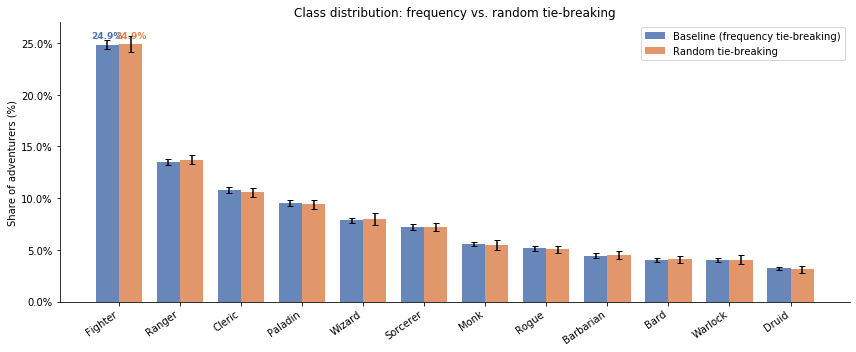

Saved to figs/fighter_tiebreak_sensitivity.png


In [7]:
classes_ordered = summary.index.tolist()

b_means = baseline_pct[classes_ordered].mean()
b_errs  = baseline_pct[classes_ordered].std()
r_means = random_tb_pct[classes_ordered].mean()
r_errs  = random_tb_pct[classes_ordered].std()

x = np.arange(len(classes_ordered))
width = 0.38

fig, ax = plt.subplots(figsize=(12, 5))

bars_b = ax.bar(x - width/2, b_means, width, yerr=b_errs, capsize=3,
                label='Baseline (frequency tie-breaking)', color='#4C72B0', alpha=0.85)
bars_r = ax.bar(x + width/2, r_means, width, yerr=r_errs, capsize=3,
                label='Random tie-breaking', color='#DD8452', alpha=0.85)

# Annotate Fighter bars
fighter_idx = classes_ordered.index('Fighter')
ax.annotate(f"{b_means['Fighter']:.1f}%",
            xy=(fighter_idx - width/2, b_means['Fighter']),
            xytext=(0, 6), textcoords='offset points',
            ha='center', fontsize=9, color='#4C72B0', fontweight='bold')
ax.annotate(f"{r_means['Fighter']:.1f}%",
            xy=(fighter_idx + width/2, r_means['Fighter']),
            xytext=(0, 6), textcoords='offset points',
            ha='center', fontsize=9, color='#DD8452', fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels(classes_ordered, rotation=35, ha='right')
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylabel('Share of adventurers (%)')
ax.set_title('Class distribution: frequency vs. random tie-breaking')
ax.legend()
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.savefig('figs/fighter_tiebreak_sensitivity.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved to figs/fighter_tiebreak_sensitivity.png")

## 6. Interpretation

The cell above prints the key numbers. Use them to update the Limitations section of main.tex:

- Report Fighter's share under random tie-breaking
- Report the delta (how much tie-breaking accounts for)
- Note Fighter remains the dominant class regardless — confirming the structural claim